# GIAI ĐOẠN 2: PHÂN TÍCH DỮ LIỆU KHÁM PHÁ (EDA)
**Dữ liệu:** `BankChurners_clean.csv` (10.127 khách hàng × 21 cột)  
**Biến mục tiêu:** `Attrition_Flag` (`0` = Khách ở lại, `1` = Khách rời bỏ)

**Mục tiêu của Notebook:**
1. Kiểm tra phân bổ của biến mục tiêu và các đặc trưng trong bộ dữ liệu sạch.
2. Tìm ra các dấu hiệu khiến khách hàng hủy thẻ tín dụng.
3. Chọn lọc các cột đặc trưng phù hợp nhất để đưa vào mô hình Học máy (Machine Learning).

## 1. Tổng quan dữ liệu

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False
mau_attrition = {0: "tab:blue", 1: "tab:orange"}


df = pd.read_csv("BankChurners_clean.csv")
print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print(f"Số ô khuyết thiếu (NaN): {df.isna().sum().sum()} | Số dòng trùng: {df.duplicated().sum()} | CLIENTNUM duy nhất: {df['CLIENTNUM'].is_unique}")

display(df.drop(columns=["CLIENTNUM"]).describe().T.round(2))

Kích thước dữ liệu: 10127 dòng, 21 cột
Số ô khuyết thiếu (NaN): 0 | Số dòng trùng: 0 | CLIENTNUM duy nhất: True


,count,mean,std,min,25%,50%,75%,max
Attrition_Flag,10127.0,0.16,0.37,0.0,0.00,0.00,0.00,1.00
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00
Dependent_count,10127.0,2.35,1.30,0.0,1.00,2.00,3.00,5.00
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00
Total_Relationship_Count,10127.0,3.81,1.55,1.0,3.00,4.00,5.00,6.00
Months_Inactive_12_mon,10127.0,2.34,1.01,0.0,2.00,2.00,3.00,6.00
Contacts_Count_12_mon,10127.0,2.46,1.11,0.0,2.00,2.00,3.00,6.00
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00
Total_Revolving_Bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00
Avg_Open_To_Buy,10127.0,7469.14,9090.69,3.0,1324.50,3474.00,9859.00,34516.00


### Từ điển biến
| Nhóm | Cột | Ý nghĩa |
|---|---|---|
| Định danh | `CLIENTNUM` | Mã khách hàng (không dùng để phân tích) |
| **Mục tiêu** | `Attrition_Flag` | **1 = Attrited (rời bỏ), 0 = Existing (ở lại)** |
| Nhân khẩu học | `Customer_Age` | Tuổi |
| | `Gender` | Giới tính (M/F) |
| | `Dependent_count` | Số người phụ thuộc |
| | `Education_Level` | Trình độ học vấn |
| | `Marital_Status` | Tình trạng hôn nhân |
| | `Income_Category` | Nhóm thu nhập hằng năm |
| | `Card_Category` | Hạng thẻ (Blue < Silver < Gold < Platinum) |
| Quan hệ với ngân hàng | `Months_on_book` | Số tháng đã gắn bó với ngân hàng |
| | `Total_Relationship_Count` | Số sản phẩm ngân hàng khách đang dùng |
| | `Months_Inactive_12_mon` | Số tháng không hoạt động trong 12 tháng |
| | `Contacts_Count_12_mon` | Số lần liên hệ với ngân hàng trong 12 tháng |
| Tài chính | `Credit_Limit` | Hạn mức tín dụng |
| | `Total_Revolving_Bal` | Dư nợ xoay vòng (nợ chưa trả hết cuối kỳ) |
| | `Avg_Open_To_Buy` | Hạn mức còn có thể tiêu = `Credit_Limit − Total_Revolving_Bal` |
| | `Avg_Utilization_Ratio` | Tỉ lệ sử dụng hạn mức = `Total_Revolving_Bal / Credit_Limit` |
| Hành vi giao dịch | `Total_Trans_Amt` | Tổng giá trị giao dịch 12 tháng |
| | `Total_Trans_Ct` | Tổng số lượt giao dịch 12 tháng |
| | `Total_Amt_Chng_Q4_Q1` | Tỉ lệ thay đổi **giá trị** giao dịch quý 4 so với quý 1 |
| | `Total_Ct_Chng_Q4_Q1` | Tỉ lệ thay đổi **số lượt** giao dịch quý 4 so với quý 1 |

**Nhận xét tổng quan dữ liệu:**
- **Dữ liệu sạch hoàn toàn:** Bộ dữ liệu gồm **10.127 khách hàng và 21 cột**, không có ô trống (`NaN`) và không có mã khách hàng (`CLIENTNUM`) nào bị trùng lặp.
- **Đặc điểm phân bố tiền bạc:** Các cột tài chính như Hạn mức tín dụng (`Credit_Limit`), Hạn mức khả dụng (`Avg_Open_To_Buy`) và Tổng tiền chi tiêu (`Total_Trans_Amt`) có giá trị Trung bình (`mean`) lớn hơn nhiều so với Trung vị ở giữa (`50%`). Nguyên nhân là ngân hàng có một nhóm khách hàng VIP hạn mức cao kéo trung bình chung lên. Vì vậy, nhóm kết hợp xem cả Trung bình và Trung vị khi so sánh hành vi.
- **Giữ nguyên nhãn `'Unknown'`:** Các ô `'Unknown'` (chưa rõ thông tin) ở 3 cột Học vấn, Thu nhập và Hôn nhân được giữ làm một nhóm riêng để bảo toàn 100% số lượng khách hàng (tránh mất hơn 30% dữ liệu).

## 2. Churn phổ biến đến đâu? — Phân bố Attrition_Flag

Số lượng:
 Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64

Tỷ lệ (%):
 Attrition_Flag
0    83.93
1    16.07
Name: proportion, dtype: float64


<Axes: xlabel='Attrition_Flag', ylabel='count'>

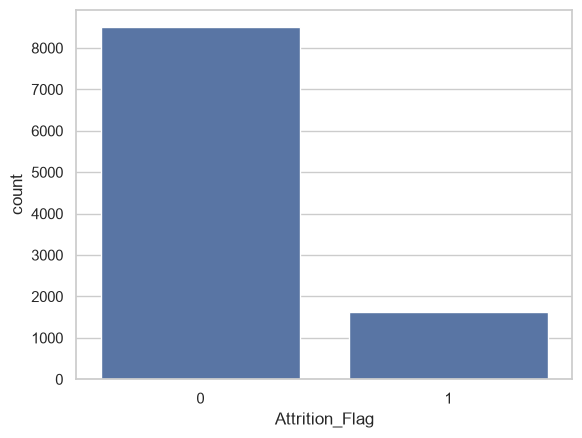

In [2]:

print("Số lượng:\n", df["Attrition_Flag"].value_counts())
print("\nTỷ lệ (%):\n", (df["Attrition_Flag"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="Attrition_Flag")

**Nhận xét tỷ lệ khách hàng rời bỏ (`Attrition_Flag`):**
- **Dữ liệu mất cân bằng (Tỷ lệ khoảng 5,22 : 1):** Ngân hàng có **8.500 khách ở lại (83,93%)** và **1.627 khách rời bỏ (16,07%)**.
- **Tại sao không chỉ nhìn vào Độ chính xác (Accuracy)?** Vì khách ở lại chiếm đa số, nếu một mô hình đoán tất cả khách hàng đều "Ở lại (0)" thì vẫn đạt độ chính xác 83,93%, nhưng thực tế lại bỏ sót 100% khách hàng hủy thẻ.
- **Hướng xử lý cho bước Học máy (ML):** Chia tập dữ liệu Train/Test giữ nguyên tỷ lệ 16,07% , ưu tiên đánh giá bằng chỉ số **Recall** cùng **F1-Score**.

## 3. Churn khác nhau thế nào theo các thuộc tính phân loại?

,count,sum,mean
Gender,,,
F,5358,930,0.1736
M,4769,697,0.1462


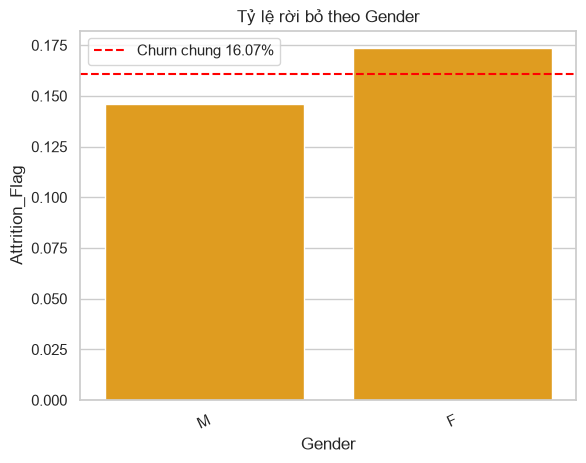

,count,sum,mean
Education_Level,,,
College,1013,154,0.1520
Doctorate,451,95,0.2106
Graduate,3128,487,0.1557
High School,2013,306,0.1520
Post-Graduate,516,92,0.1783
Uneducated,1487,237,0.1594
Unknown,1519,256,0.1685


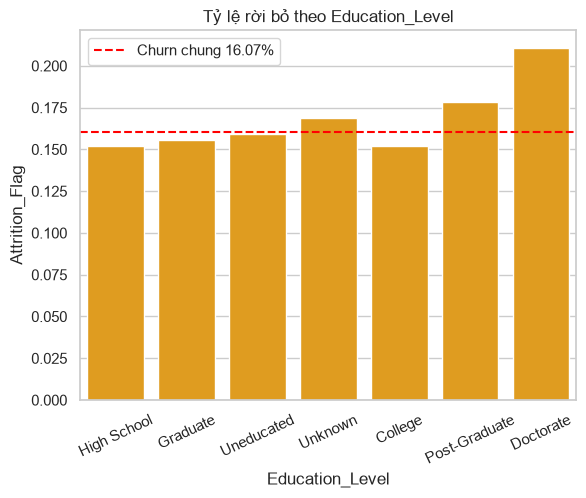

,count,sum,mean
Marital_Status,,,
Divorced,748,121,0.1618
Married,4687,709,0.1513
Single,3943,668,0.1694
Unknown,749,129,0.1722


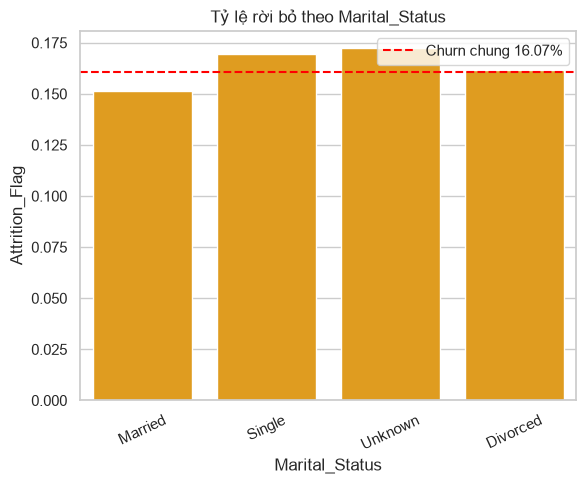

,count,sum,mean
Income_Category,,,
$120K +,727,126,0.1733
$40K - $60K,1790,271,0.1514
$60K - $80K,1402,189,0.1348
$80K - $120K,1535,242,0.1577
Less than $40K,3561,612,0.1719
Unknown,1112,187,0.1682


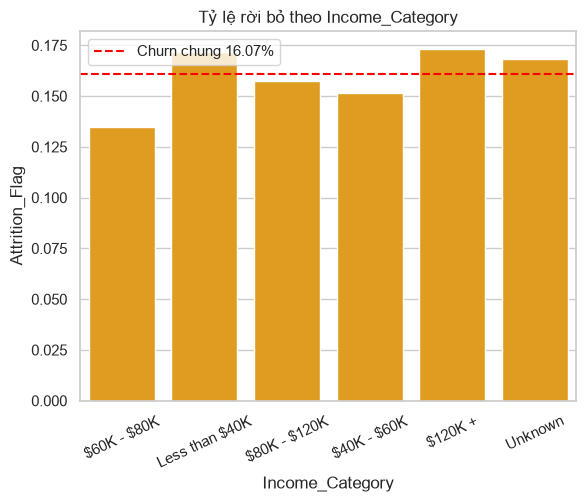

,count,sum,mean
Card_Category,,,
Blue,9436,1519,0.1610
Gold,116,21,0.1810
Platinum,20,5,0.2500
Silver,555,82,0.1477


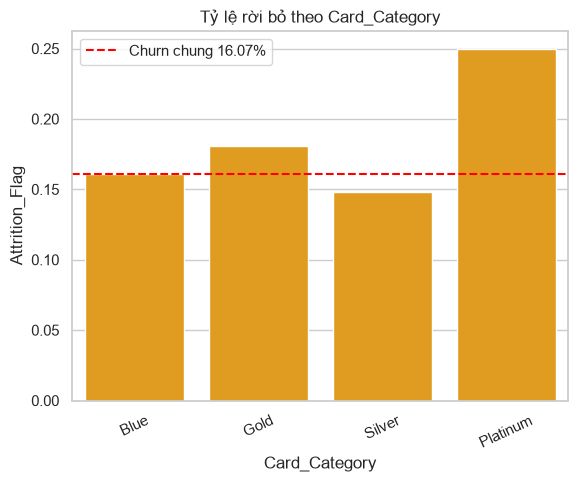

In [3]:
cot_phan_loai = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]

for ten_cot in cot_phan_loai:
    bang = df.groupby(ten_cot)["Attrition_Flag"].agg(["count", "sum", "mean"]).round(4)
    display(bang)
    
    sns.barplot(data=df, x=ten_cot, y="Attrition_Flag", color="orange", errorbar=None)
    plt.axhline(0.1607, color="red", linestyle="--", label="Churn chung 16.07%")
    plt.title("Tỷ lệ rời bỏ theo " + ten_cot)
    plt.xticks(rotation=25) 
    plt.legend()
    plt.show()

**Nhận xét theo 5 thuộc tính phân loại dạng chữ:**
- **Giới tính (`Gender`):** Tỷ lệ rời bỏ ở Nữ (17,36%) và Nam (14,62%) chênh lệch rất nhỏ (chỉ 2,74%).
- **Trình độ học vấn (`Education_Level`):** Dao động quanh mức 15% – 21%, không có quy luật học vấn càng cao hay càng thấp thì càng dễ hủy thẻ.
- **Tình trạng hôn nhân (`Marital_Status`):** Các nhóm Đã kết hôn (15,13%), Độc thân (16,94%), Ly hôn (16,18%) và Unknown (17,22%) có tỷ lệ rời bỏ gần như bằng nhau.
- **Mức thu nhập (`Income_Category`):** Nhóm thu nhập thấp dưới 40K USD (17,19%) và nhóm thu nhập cao trên 120K USD (17,33%) có tỷ lệ hủy thẻ tương đương nhau.
- **Hạng thẻ (`Card_Category`):** Hơn 93% khách hàng dùng thẻ Blue (tỷ lệ hủy 16,10%). Nhóm thẻ Platinum có tỷ lệ hủy 25% nhưng toàn ngân hàng chỉ có đúng 20 khách (5 người rời bỏ) nên cỡ mẫu quá nhỏ, không mang tính đại diện.

**-> Kết luận:** Cả 5 biến dạng chữ đều có tỷ lệ rời bỏ bám sát đường trung bình chung 16,07%, không giúp phân biệt khách hàng sắp hủy thẻ. Vì vậy, nhóm quyết định loại bỏ 5 cột dạng chữ này ở bước xây dựng mô hình Machine Learning.

## 4. Ma trận tương quan (Correlation Heatmap)
Trước khi đi sâu vào từng thuộc tính định lượng, ta tính hệ số tương quan tuyến tính Pearson ($r$) trên toàn bộ 14 biến số để:
1. Xác định nhóm biến nào có liên kết mạnh nhất với trạng thái rời bỏ (`Attrition_Flag`).
2. Phát hiện các cặp biến đầu vào bị chồng lấn thông tin (Đa cộng tuyến).

--- XẾP HẠNG TƯƠNG QUAN VỚI ATTRITION_FLAG ---
Total_Trans_Ct             -0.3714
Total_Ct_Chng_Q4_Q1        -0.2901
Total_Revolving_Bal        -0.2631
Avg_Utilization_Ratio      -0.1784
Total_Trans_Amt            -0.1686
Total_Relationship_Count   -0.1500
Total_Amt_Chng_Q4_Q1       -0.1311
Credit_Limit               -0.0239
Avg_Open_To_Buy            -0.0003
Months_on_book              0.0137
Customer_Age                0.0182
Dependent_count             0.0190
Months_Inactive_12_mon      0.1524
Contacts_Count_12_mon       0.2045
Name: Attrition_Flag, dtype: float64


<Axes: >

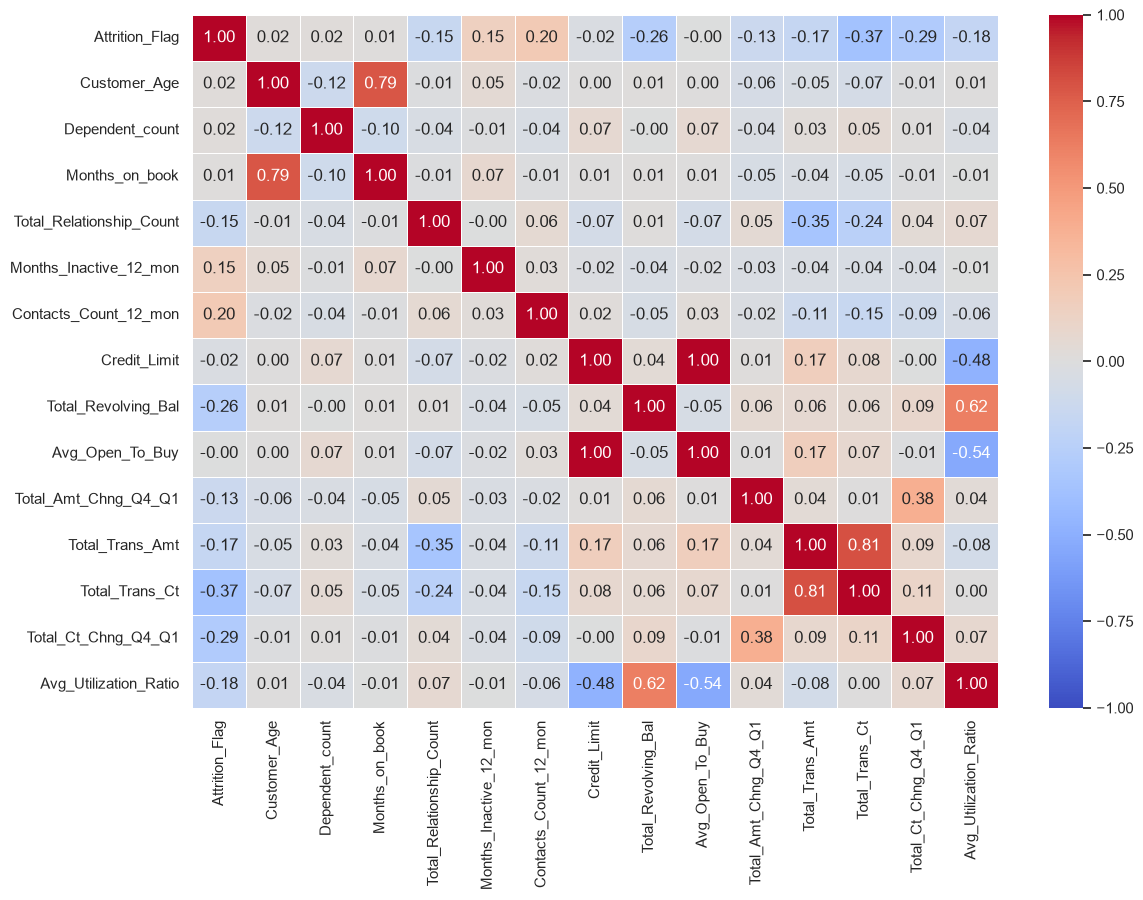

In [4]:

ma_tran_corr = df.drop(columns=["CLIENTNUM"]).corr(numeric_only=True)

print("--- XẾP HẠNG TƯƠNG QUAN VỚI ATTRITION_FLAG ---")
print(ma_tran_corr["Attrition_Flag"].drop("Attrition_Flag").sort_values().round(4))

plt.figure(figsize=(13, 9))
sns.heatmap(ma_tran_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)

**Nhận xét từ Bản đồ nhiệt tương quan (Correlation Heatmap):**
1. **Mức độ liên hệ với việc rời bỏ (`Attrition_Flag`):**
   - **Tương quan âm mạnh nhất** (giá trị càng cao càng ít rời bỏ): Đứng đầu là Tổng số lần quẹt thẻ `Total_Trans_Ct` (**-0,37**), Đà thay đổi số lần quẹt `Total_Ct_Chng_Q4_Q1` (**-0,29**), Dư nợ xoay vòng `Total_Revolving_Bal` (**-0,26**) và Tỷ lệ sử dụng hạn mức `Avg_Utilization_Ratio` (**-0,18**).
   - **Tương quan dương mạnh nhất** (giá trị càng cao càng dễ rời bỏ): Số lần gọi tổng đài `Contacts_Count_12_mon` (**+0,20**) và Số tháng ngừng dùng thẻ `Months_Inactive_12_mon` (**+0,15**).
   - **Không có tương quan:**
      + Ba biến số nhân khẩu học gồm Tuổi (`Customer_Age`: **+0,018**), Số tháng gắn bó (`Months_on_book`: **+0,014**) và Số người phụ thuộc (`Dependent_count`: **+0,019**) đều có hệ số tương quan gần bằng **0**.
      + Hai biến số hành vi hạn mức tín dụng(`Credit_Limit`: **-0,02**), hạn mức tiêu khả dụng(`Avg_Open_To_Buy`: **-0,00**) đều có hệ số tương quan gần bằng **0**.

2. **Đánh giá tương quan chéo giữa các biến đầu vào:**
   - **`Total_Trans_Ct` và `Total_Trans_Amt` ($r = 0,81$):** Tương quan dương chặt nhưng nhóm giữ lại cả 2 cột để mô hình cây quyết định phân biệt được giá trị chi tiêu trung bình trên mỗi lần quẹt thẻ.

## 5. Kiểm định nhóm Biến số Nhân khẩu học (`Customer_Age`, `Months_on_book`, `Dependent_count`)

Trung vị (Median) theo nhóm Attrition_Flag:


,Customer_Age,Months_on_book,Dependent_count
Attrition_Flag,,,
0,46.0,36.0,2.0
1,47.0,36.0,2.0


<Axes: xlabel='Customer_Age', ylabel='Density'>

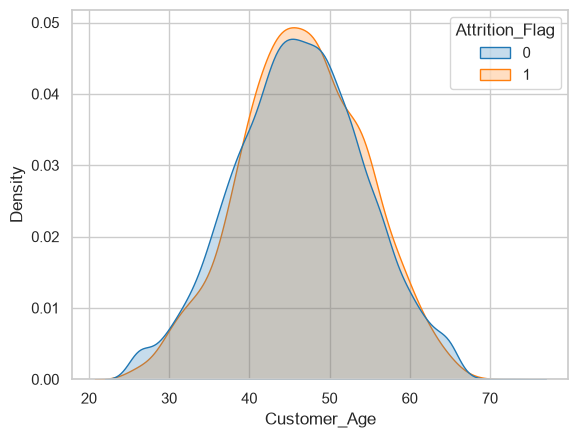

In [18]:
cot_nhankhau = ["Customer_Age", "Months_on_book", "Dependent_count"]
print("Trung vị (Median) theo nhóm Attrition_Flag:")
display(df.groupby("Attrition_Flag")[cot_nhankhau].median())
sns.kdeplot(data=df, x="Customer_Age", hue="Attrition_Flag", common_norm=False, fill=True, palette=mau_attrition)

<Axes: xlabel='Months_on_book', ylabel='Density'>

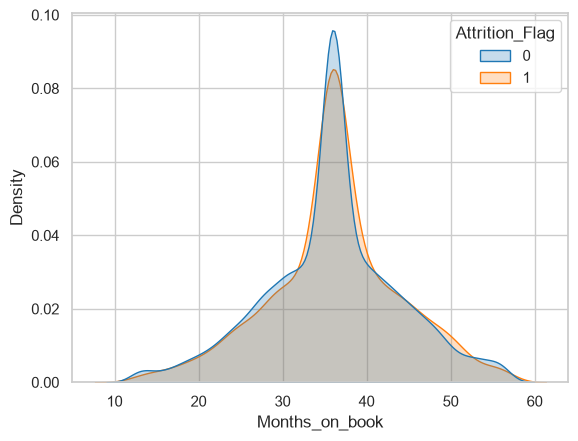

In [6]:
sns.kdeplot(data=df, x="Months_on_book", hue="Attrition_Flag", common_norm=False, fill=True, palette=mau_attrition)

<Axes: xlabel='Dependent_count', ylabel='Attrition_Flag'>

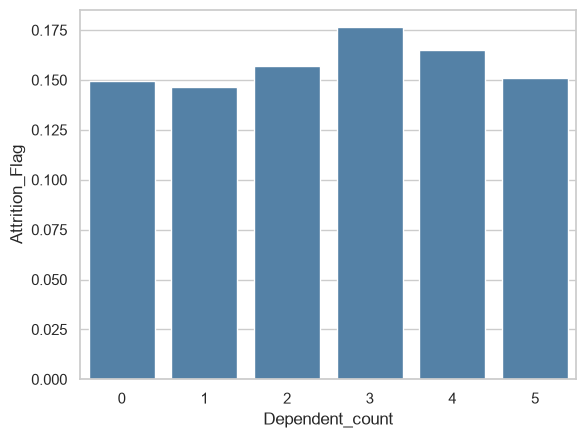

In [7]:
sns.barplot(data=df, x="Dependent_count", y="Attrition_Flag", color="steelblue", errorbar=None)

**Nhận xét nhóm Biến số Nhân khẩu học (`Customer_Age`, `Months_on_book`, `Dependent_count`):**
- Biểu đồ phân phối của nhóm ở lại (màu xanh) và nhóm rời bỏ (màu cam) trên cả hai biến **Độ tuổi (`Customer_Age`)** (trung vị 46 so với 47 tuổi) và **Số tháng gắn bó (`Months_on_book`)** (cùng trung vị 36 tháng) nằm chồng khít lên nhau.
- Tỷ lệ rời bỏ theo **Số người phụ thuộc (`Dependent_count`)** từ 0 đến 5 người cũng giữ đều quanh mức trung bình ngành 16,07% (dao động 15% – 17%).
- **-> Kết luận:** Kết hợp với Mục 3 (5 biến phân loại) và Mục 4 (tương quan $|r| < 0,02$), nhóm khẳng định các biến nhân khẩu học không phải là nguyên nhân gây hủy thẻ và quyết định loại bỏ cả 3 biến số này ở bước xây dựng mô hình Machine Learning.

## 6. Phân tích chuyên sâu Hành vi sử dụng thẻ 

#### 6.1 phân tích theo số tiền giao dịch và số lượt giao dịch

In [8]:
cot_hanhvi = [
    "Total_Trans_Ct", "Total_Trans_Amt", "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1",
    "Total_Revolving_Bal", "Avg_Utilization_Ratio", "Credit_Limit",
    "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon"
]

display(df.groupby("Attrition_Flag")[cot_hanhvi].agg(["mean", "median"]).T.round(2))

Attrition_Flag                         0        1
Total_Trans_Ct           mean      68.67    44.93
                         median    71.00    43.00
Total_Trans_Amt          mean    4654.66  3095.03
                         median  4100.00  2329.00
Total_Ct_Chng_Q4_Q1      mean       0.74     0.55
                         median     0.72     0.53
Total_Amt_Chng_Q4_Q1     mean       0.77     0.69
                         median     0.74     0.70
Total_Revolving_Bal      mean    1256.60   672.82
                         median  1364.00     0.00
Avg_Utilization_Ratio    mean       0.30     0.16
                         median     0.21     0.00
Credit_Limit             mean    8726.88  8136.04
                         median  4643.50  4178.00
Total_Relationship_Count mean       3.91     3.28
                         median     4.00     3.00
Months_Inactive_12_mon   mean       2.27     2.69
                         median     2.00     3.00
Contacts_Count_12_mon    mean       2.36     2.97
                         median     2.00     3.00

<Axes: xlabel='Total_Trans_Ct', ylabel='Density'>

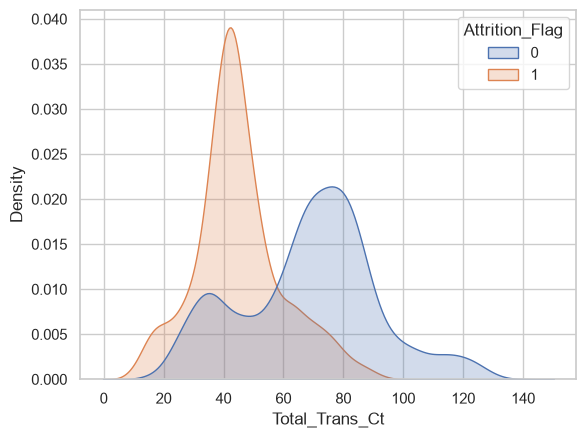

In [9]:
sns.kdeplot(data=df, x="Total_Trans_Ct", hue="Attrition_Flag", common_norm=False, fill=True)

<Axes: xlabel='Total_Trans_Ct', ylabel='Total_Trans_Amt'>

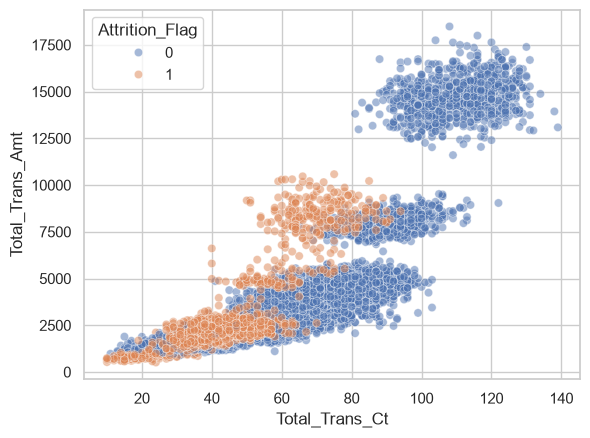

In [10]:
sns.scatterplot(data=df, x="Total_Trans_Ct", y="Total_Trans_Amt", hue="Attrition_Flag", alpha=0.5)

<Axes: xlabel='Total_Ct_Chng_Q4_Q1', ylabel='Density'>

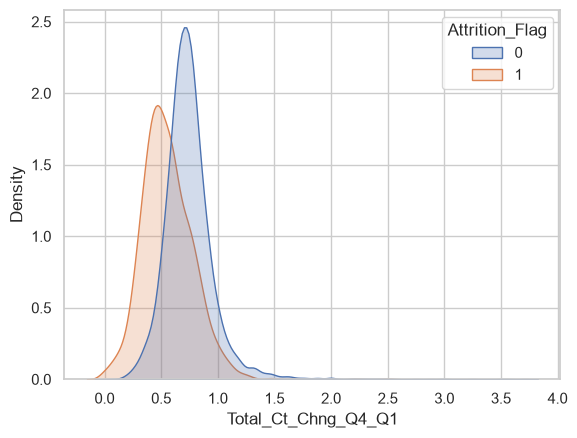

In [11]:
sns.kdeplot(data=df, x="Total_Ct_Chng_Q4_Q1", hue="Attrition_Flag", common_norm=False, fill=True)

**Nhận xét về Hành vi quẹt thẻ và Chi tiêu:**
1. **Tổng số lần quẹt thẻ trong năm (`Total_Trans_Ct` - Hình 1):**
   - Nhóm rời bỏ (màu cam) giao dịch rất ít, tập trung đông nhất ở vùng **40 – 45 lần/năm** (trung vị 43 lần), thấp hơn hẳn so với nhóm ở lại (trung vị 71 lần).
   - Hai đường phân phối giao nhau ngay sát mốc **60 lần/năm** (~5 lần/tháng). Khách hàng quẹt từ 60 lần/năm trở xuống có rủi ro hủy thẻ rất cao.
2. **Quan hệ giữa Số lần quẹt và Tổng tiền chi tiêu (Scatter Plot - Hình 2):**
   - Dữ liệu tách thành 3 cụm chi tiêu: Phổ thông (`< 5.000 USD`), Trung lưu (`5.000 – 10.000 USD`) và VIP (`> 10.000 USD`).
   - Phần lớn các điểm màu cam (khách rời bỏ) tập trung ở góc dưới bên trái: **quẹt `<= 60 lần` và chi tiêu `<= 5.000 USD`**. Hầu như không có khách hàng nào quẹt trên 80 lần và tiêu trên 10.000 USD mà hủy thẻ.
3. **Đà thay đổi số lần quẹt Quý 4 so với Quý 1 (`Total_Ct_Chng_Q4_Q1` - Hình 3):**
   - Đường phân phối của nhóm rời bỏ (màu cam) lệch hẳn về bên trái với đỉnh quanh mức **0,53** (trung bình 0,55), trong khi nhóm ở lại đạt đỉnh quanh mức **0,72** (trung bình 0,74).
   - Khi chỉ số này rơi xuống **dưới 0,5** (số lần quẹt Quý 4 giảm còn chưa tới một nửa Quý 1), khách hàng đang giảm sử dụng thẻ đột ngột trước khi đóng thẻ.
   

#### 6.2 Phân tích theo Dư nợ xoay vòng, Số lần gọi tổng đài, Tháng ngừng dùng và Số sản phẩm

<Axes: xlabel='Total_Revolving_Bal', ylabel='Density'>

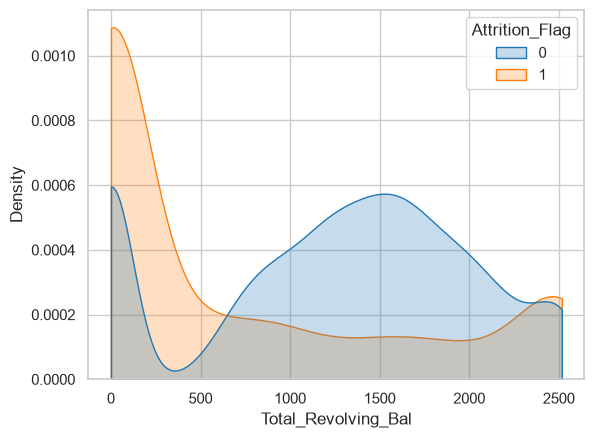

In [12]:

sns.kdeplot(data=df, x="Total_Revolving_Bal", hue="Attrition_Flag", common_norm=False, fill=True, cut=0, palette=mau_attrition)


<Axes: xlabel='Contacts_Count_12_mon', ylabel='Attrition_Flag'>

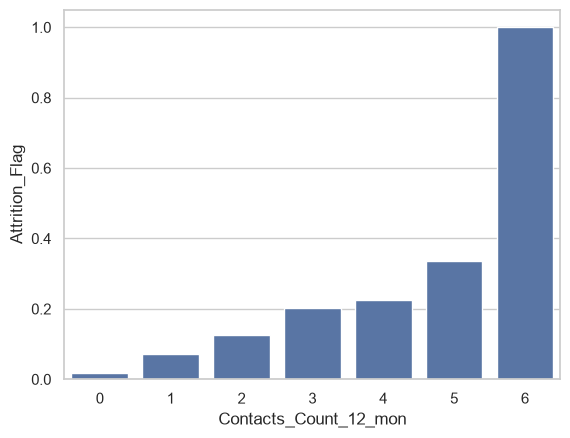

In [13]:
sns.barplot(data=df, x="Contacts_Count_12_mon", y="Attrition_Flag", errorbar=None)

<Axes: xlabel='Months_Inactive_12_mon', ylabel='Attrition_Flag'>

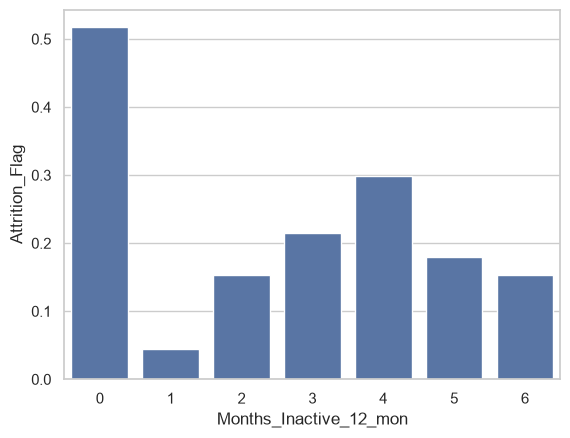

In [14]:
sns.barplot(data=df, x="Months_Inactive_12_mon", y="Attrition_Flag", errorbar=None)

<Axes: xlabel='Total_Relationship_Count', ylabel='Attrition_Flag'>

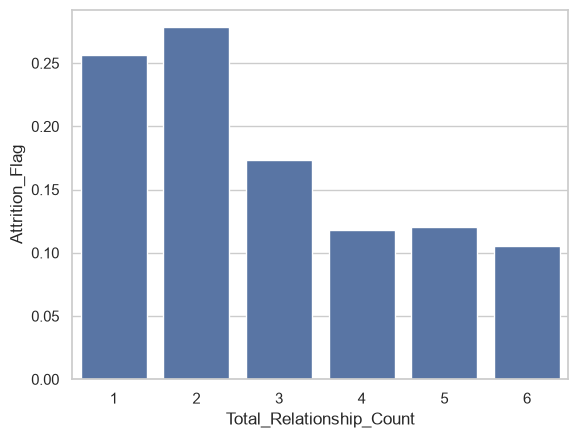

In [15]:
sns.barplot(data=df, x="Total_Relationship_Count", y="Attrition_Flag", errorbar=None)

**Nhận xét 4 dấu hiệu rủi ro phụ trợ:**
1. **Dư nợ xoay vòng cuối kỳ (`Total_Revolving_Bal` - Hình 1):**
   - Nhóm rời bỏ (màu cam) vọt lên rất cao ở ngay vạch **`0 USD`** (trung vị bằng 0 USD, chiếm 54,89% tổng số người hủy thẻ) và rất thấp ở vùng trên **500 USD**. Ngược lại, nhóm ở lại tập trung đông ở mức **800 – 1.800 USD** (trung vị 1.364 USD).
   - Nhóm có dư nợ **`< 500 USD`** chiếm tới 61,34% tổng số khách rời bỏ của ngân hàng, phản ánh hành vi tất toán hết nợ trước khi hủy thẻ.
2. **Số lần liên hệ tổng đài CSKH (`Contacts_Count_12_mon` - Hình 2):**
   - Gọi tổng đài càng nhiều thì tỷ lệ hủy thẻ càng tăng: từ 0 – 2 lần rất an toàn (1,75% – 12,49%), nhưng từ **`>= 3 lần`** tỷ lệ rời bỏ tăng lên trên 20% – 33%, và đặc biệt **gọi 6 lần thì 100% khách hàng đều hủy thẻ** (54/54 người).
3. **Số tháng ngừng giao dịch (`Months_Inactive_12_mon` - Hình 3):**
   - Rủi ro rời bỏ tập trung cao nhất khi khách ngừng dùng thẻ từ **`3 – 4 tháng`** (tỷ lệ hủy thẻ 21,48% – 29,89%, chiếm 58,76% tổng số ca rời bỏ).
   - Mốc `0 tháng` có tỷ lệ 51,72% nhưng cỡ mẫu quá nhỏ (chỉ có 29 người trên toàn ngân hàng). Mốc `6 tháng` giảm về 15,32% vì người muốn hủy đã đóng thẻ ở tháng thứ 3 – 4, số còn lại chủ yếu là thẻ mở dự phòng để quên trong ví.
4. **Tổng số sản phẩm sử dụng (`Total_Relationship_Count` - Hình 4):**
   - Khách hàng chỉ dùng **`1 – 2 sản phẩm`** có tỷ lệ rời bỏ rất cao (25,60% – 27,76%) do ít ràng buộc với ngân hàng. Khi khách dùng từ **3 sản phẩm trở lên**, tỷ lệ rời bỏ giảm mạnh xuống mức 10,56% – 17,35%.

## 7. Tổng kết EDA & Chọn lọc đặc trưng cho Machine Learning

1. **Chân dung khách hàng có nguy cơ rời bỏ cao:**
   Quyết định hủy thẻ không phụ thuộc vào nhân khẩu học mà được nhận diện qua **6 dấu hiệu hành vi**:
   - (1) Tần suất quẹt thẻ thấp: `Total_Trans_Ct <= 60` lần/năm.
   - (2) Đà quẹt thẻ cuối năm giảm sâu: `Total_Ct_Chng_Q4_Q1 < 0,5`.
   - (3) Dư nợ xoay vòng thấp: `Total_Revolving_Bal < 500` USD (đặc biệt là `= 0` USD).
   - (4) Liên hệ tổng đài nhiều lần: `Contacts_Count_12_mon >= 3` lần/năm.
   - (5) Ngừng dùng thẻ kéo dài: `Months_Inactive_12_mon >= 3` tháng.
   - (6) Ít gắn kết dịch vụ: `Total_Relationship_Count <= 2` sản phẩm.

2. **Chọn lọc đặc trưng (Feature Selection) cho mô hình Học máy :**
   Từ 21 cột của bộ dữ liệu sạch (trừ biến mục tiêu `Attrition_Flag` còn 20 biến đầu vào), nhóm lọc bỏ 11 cột và giữ lại 9 biến hành vi cốt lõi:
   - Bỏ cột `CLIENTNUM`: Mã định danh cá nhân, không mang ý nghĩa dự báo.
   - Bỏ cột `Avg_Open_To_Buy` với `Credit_Limit` có tương quan với biến mục tiên gần bằng 0.
   - Bỏ 5 cột phân loại dạng chữ (`Gender`, `Education_Level`, `Marital_Status`, `Income_Category`, `Card_Category`): Tỷ lệ rời bỏ đồng đều quanh mức 16,07%.
   - Bỏ 3 cột số nhân khẩu học (`Customer_Age`, `Dependent_count`, `Months_on_book`): Tương quan gần bằng 0 ($|r| < 0,02$) và phân phối chồng khít giữa hai nhóm khách hàng.
   - Giữ lại 9 biến số hành vi & tài chính: Đưa vào huấn luyện mô hình `RandomForestClassifier`.